In [3]:
# !pip install -U torch torchvision transformers datasets huggingface_hub accelerate tqdm

In [4]:
# %pip install -q huggingface_hub tqdm

In [5]:
# %pip install -e "./models/source/siglip2" -e "./models/source/timm" einops

In [6]:
# %pip install scipy

In [1]:
import torch

torch.set_num_threads(4)

In [2]:
# Standard library
import csv
import gc
import hashlib
import importlib
import importlib.metadata
import inspect
import json
import math
import os
import sys
import platform
import random
import shutil
import tempfile
import time
import traceback
import zipfile
from collections import Counter
from contextlib import contextmanager
from datetime import datetime
from pathlib import Path
from urllib.request import Request, urlopen

# Resolve shared assets and imports without changing the working directory.
PROJECT_ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                     if (p / "baseline_models.py").is_file() and (p / "report_1").is_dir()
                     and (p / "report_2").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the Deep Learning Project directory.")
ROOT = PROJECT_ROOT
(PROJECT_ROOT / "models" / "source").mkdir(parents=True, exist_ok=True)
(PROJECT_ROOT / "models" / "checkpoints").mkdir(parents=True, exist_ok=True)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
REPORT1_DIR = PROJECT_ROOT / "report_1"
REPORT2_DIR = PROJECT_ROOT / "report_2"

if str(REPORT1_DIR) not in sys.path:
    sys.path.insert(0, str(REPORT1_DIR))

# Scientific computing, images, and progress
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.profiler import ProfilerActivity, profile, record_function
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchvision.transforms.functional import pil_to_tensor, to_tensor

# Hugging Face
from datasets import load_dataset
from huggingface_hub import hf_hub_download, snapshot_download
from transformers import AutoImageProcessor, AutoModel

# create data split 

In [3]:
# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

IMAGENET_ROOT = PROJECT_ROOT / "datasets/imagenet"
ADE20K_ROOT = PROJECT_ROOT / "datasets/ade20k/ADEChallengeData2016"
SPLIT_DIR = PROJECT_ROOT / "datasets/splits"

SPLIT_DIR.mkdir(parents=True, exist_ok=True)

IMAGENET_TRAIN_PER_CLASS = 100
IMAGENET_DEV_PER_CLASS = 20

# ============================================================
# 2. IMAGENET: CHECK FOR EXISTING SPLIT
# ============================================================

imagenet_split_path = SPLIT_DIR / "imagenet_split.json"

imagenet_train_dir = (
    IMAGENET_ROOT / "ILSVRC/Data/CLS-LOC/train"
)

imagenet_val_dir = (
    IMAGENET_ROOT / "ILSVRC/Data/CLS-LOC/val"
)

imagenet_val_csv = IMAGENET_ROOT / "LOC_val_solution.csv"

if imagenet_split_path.is_file():

    print("Existing ImageNet split found. Loading...")

    with open(imagenet_split_path, encoding="utf-8") as f:
        imagenet_split = json.load(f)

    if imagenet_split["seed"] != SEED:
        raise ValueError("ImageNet split uses a different seed.")

    train_indices = imagenet_split["train_indices"]
    dev_indices = imagenet_split["dev_indices"]

    train_files = imagenet_split["train_files"]
    dev_files = imagenet_split["dev_files"]
    val_files = imagenet_split["val_files"]

else:

    # ========================================================
    # 3. CREATE IMAGENET SPLIT ONLY IF MISSING
    # ========================================================

    print("No existing ImageNet split. Creating...")

    if not imagenet_train_dir.is_dir():
        raise FileNotFoundError(imagenet_train_dir)

    if not imagenet_val_dir.is_dir():
        raise FileNotFoundError(imagenet_val_dir)

    # Load local filenames and labels, not image contents.
    imagenet_full_train = ImageFolder(
        root=str(imagenet_train_dir)
    )

    targets = np.asarray(imagenet_full_train.targets)

    assert len(imagenet_full_train) == 1_281_167
    assert len(imagenet_full_train.classes) == 1000

    rng = np.random.default_rng(SEED)

    train_indices = []
    dev_indices = []

    # Stratified sampling: 100 train + 20 dev per class.
    for class_id in range(1000):

        class_indices = np.where(targets == class_id)[0]

        required = (
            IMAGENET_TRAIN_PER_CLASS
            + IMAGENET_DEV_PER_CLASS
        )

        if len(class_indices) < required:
            raise ValueError(
                f"Class {class_id} has insufficient images."
            )

        shuffled = rng.permutation(class_indices)

        train_indices.extend(
            shuffled[:IMAGENET_TRAIN_PER_CLASS].tolist()
        )

        dev_indices.extend(
            shuffled[
                IMAGENET_TRAIN_PER_CLASS:required
            ].tolist()
        )

    rng.shuffle(train_indices)
    rng.shuffle(dev_indices)

    # Save paths as well as indices.
    # Filenames remain identifiable if dataset ordering changes.
    def imagenet_relative_path(index):
        return (
            Path(imagenet_full_train.samples[index][0])
            .relative_to(IMAGENET_ROOT)
            .as_posix()
        )

    train_files = [
        imagenet_relative_path(i) for i in train_indices
    ]

    dev_files = [
        imagenet_relative_path(i) for i in dev_indices
    ]

    val_paths = sorted(
        p for p in imagenet_val_dir.iterdir()
        if p.suffix.lower() in {".jpeg", ".jpg"}
    )

    val_files = [
        p.relative_to(IMAGENET_ROOT).as_posix()
        for p in val_paths
    ]

    # Confirm the CSV refers to these validation images.
    # This does not establish official classification labels.
    if imagenet_val_csv.is_file():

        with open(
            imagenet_val_csv,
            newline="",
            encoding="utf-8-sig"
        ) as f:
            reader = csv.DictReader(f)
            csv_ids = {row["ImageId"] for row in reader}

        assert csv_ids == {p.stem for p in val_paths}

# ============================================================
# 4. VERIFY IMAGENET SPLIT
# ============================================================

assert len(train_indices) == len(train_files) == 100_000
assert len(dev_indices) == len(dev_files) == 20_000
assert len(val_files) == 50_000

assert len(set(train_indices)) == len(train_indices)
assert len(set(dev_indices)) == len(dev_indices)
assert set(train_indices).isdisjoint(dev_indices)

assert len(set(train_files + dev_files + val_files)) == 170_000

train_counts = Counter(
    Path(p).parent.name for p in train_files
)

dev_counts = Counter(
    Path(p).parent.name for p in dev_files
)

assert len(train_counts) == 1000
assert len(dev_counts) == 1000

assert set(train_counts) == set(dev_counts)
assert set(train_counts.values()) == {100}
assert set(dev_counts.values()) == {20}

print("\nImageNet split verified.")
print("Train:", len(train_files))
print("Dev:", len(dev_files))
print("Final test:", len(val_files))
print("Class balance: PASSED")
print("No overlap: PASSED")

# Save only if the split did not already exist.
if not imagenet_split_path.exists():

    imagenet_split = {
        "seed": SEED,
        "train_indices": train_indices,
        "dev_indices": dev_indices,
        "train_files": train_files,
        "dev_files": dev_files,
        "val_files": val_files,
        "class_to_idx": imagenet_full_train.class_to_idx
    }

    with open(
        imagenet_split_path,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(imagenet_split, f)

    print("New ImageNet split saved.")

else:
    print("Existing ImageNet split preserved.")

# ============================================================
# 5. ADE20K: CHECK FOR EXISTING SPLIT
# ============================================================

ade_split_path = SPLIT_DIR / "ade20k_split.json"

if ade_split_path.is_file():

    print("\nExisting ADE20K split found. Loading...")

    with open(ade_split_path, encoding="utf-8") as f:
        ade_split = json.load(f)

    if (
        ade_split.get("source") != "local_adechallengedata2016"
        or ade_split.get("seed") != SEED
    ):
        raise ValueError(
            "Existing ADE20K split has a different "
            "source or seed. It has not been overwritten."
        )

    ade_train_indices = ade_split["train_indices"]
    ade_dev_indices = ade_split["dev_indices"]

    ade_train_files = ade_split["train_files"]
    ade_dev_files = ade_split["dev_files"]
    ade_val_files = ade_split["val_files"]

else:

    # ========================================================
    # 6. CREATE ADE20K SPLIT ONLY IF MISSING
    # ========================================================

    print("\nNo existing ADE20K split. Creating...")

    ade_images = ADE20K_ROOT / "images"
    ade_masks = ADE20K_ROOT / "annotations"

    def load_ade_pairs(split):

        image_dir = ade_images / split
        mask_dir = ade_masks / split

        if not image_dir.is_dir():
            raise FileNotFoundError(image_dir)

        if not mask_dir.is_dir():
            raise FileNotFoundError(mask_dir)

        images = sorted(
            p for p in image_dir.iterdir()
            if p.suffix.lower() in {".jpg", ".jpeg"}
        )

        masks = sorted(
            p for p in mask_dir.iterdir()
            if p.suffix.lower() == ".png"
        )

        image_map = {p.stem: p for p in images}
        mask_map = {p.stem: p for p in masks}

        if len(image_map) != len(images):
            raise ValueError("Duplicate ADE image identifiers.")

        if len(mask_map) != len(masks):
            raise ValueError("Duplicate ADE mask identifiers.")

        if image_map.keys() != mask_map.keys():
            raise ValueError(
                f"Unmatched images/masks in {split}."
            )

        return [
            (image_map[k], mask_map[k])
            for k in sorted(image_map)
        ]

    ade_full_train = load_ade_pairs("training")
    ade_test = load_ade_pairs("validation")

    assert len(ade_full_train) == 20_210
    assert len(ade_test) == 2_000

    rng = np.random.default_rng(SEED)

    indices = rng.permutation(len(ade_full_train))

    split_point = int(0.90 * len(indices))

    ade_train_indices = indices[:split_point].tolist()
    ade_dev_indices = indices[split_point:].tolist()

    # Save image/mask pairs without copying the files.
    def relative_ade_pair(pair):

        image, mask = pair

        return {
            "image": image.relative_to(
                ADE20K_ROOT
            ).as_posix(),
            "mask": mask.relative_to(
                ADE20K_ROOT
            ).as_posix()
        }

    ade_train_files = [
        relative_ade_pair(ade_full_train[i])
        for i in ade_train_indices
    ]

    ade_dev_files = [
        relative_ade_pair(ade_full_train[i])
        for i in ade_dev_indices
    ]

    ade_val_files = [
        relative_ade_pair(pair)
        for pair in ade_test
    ]

# ============================================================
# 7. VERIFY ADE20K SPLIT
# ============================================================

assert len(ade_train_indices) == len(ade_train_files) == 18_189
assert len(ade_dev_indices) == len(ade_dev_files) == 2_021
assert len(ade_val_files) == 2_000

assert len(set(ade_train_indices)) == len(ade_train_indices)
assert len(set(ade_dev_indices)) == len(ade_dev_indices)

assert set(ade_train_indices).isdisjoint(ade_dev_indices)

assert (
    set(ade_train_indices) | set(ade_dev_indices)
) == set(range(20_210))

all_ade = ade_train_files + ade_dev_files + ade_val_files

ade_image_paths = [entry["image"] for entry in all_ade]
ade_mask_paths = [entry["mask"] for entry in all_ade]

assert len(set(ade_image_paths)) == 22_210
assert len(set(ade_mask_paths)) == 22_210

for entry in all_ade:
    assert (
        Path(entry["image"]).stem
        == Path(entry["mask"]).stem
    )

print("\nADE20K split verified.")
print("Train:", len(ade_train_files))
print("Dev:", len(ade_dev_files))
print("Final test:", len(ade_val_files))
print("No overlap: PASSED")
print("Image/mask pairing: PASSED")

# Save only if the split did not already exist.
if not ade_split_path.exists():

    ade_split = {
        "source": "local_adechallengedata2016",
        "seed": SEED,
        "train_indices": ade_train_indices,
        "dev_indices": ade_dev_indices,
        "train_files": ade_train_files,
        "dev_files": ade_dev_files,
        "val_files": ade_val_files
    }

    with open(
        ade_split_path,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(ade_split, f)

    print("New ADE20K split saved.")

else:
    print("Existing ADE20K split preserved.")

# ============================================================
# 8. FINAL SUMMARY
# ============================================================

print("\n========== FINAL SPLITS ==========")

print("\nImageNet")
print("Train:", len(train_files))
print("Dev:", len(dev_files))
print("Final test:", len(val_files))

print("\nADE20K")
print("Train:", len(ade_train_files))
print("Dev:", len(ade_dev_files))
print("Final test:", len(ade_val_files))

print("\nAll available splits verified.")
print("No downloads or existing split overwrites.")


Existing ImageNet split found. Loading...

ImageNet split verified.
Train: 100000
Dev: 20000
Final test: 50000
Class balance: PASSED
No overlap: PASSED
Existing ImageNet split preserved.

Existing ADE20K split found. Loading...

ADE20K split verified.
Train: 18189
Dev: 2021
Final test: 2000
No overlap: PASSED
Image/mask pairing: PASSED
Existing ADE20K split preserved.

========== FINAL SPLITS ==========

ImageNet
Train: 100000
Dev: 20000
Final test: 50000

ADE20K
Train: 18189
Dev: 2021
Final test: 2000

All available splits verified.
No downloads or existing split overwrites.


In [4]:
SPLIT_DIR = PROJECT_ROOT / "datasets/splits"

with open(SPLIT_DIR / "imagenet_split.json") as f:
    im = json.load(f)

with open(SPLIT_DIR / "ade20k_split.json") as f:
    ade = json.load(f)

# ImageNet filenames
im_train = im["train_files"]
im_dev = im["dev_files"]
im_test = im["val_files"]

# ADE20K image/mask pairs
ade_train = ade["train_files"]
ade_dev = ade["dev_files"]
ade_test = ade["val_files"]

print("ImageNet")
print("Train:", len(im_train))
print("Dev:", len(im_dev))
print("Test:", len(im_test))

assert len(im_train) == 100_000
assert len(im_dev) == 20_000
assert len(im_test) == 50_000

# Check there are no repeated images across splits.
assert len(set(im_train + im_dev + im_test)) == 170_000

# Check the number of images per class.
train_counts = Counter(Path(p).parent.name for p in im_train)
dev_counts = Counter(Path(p).parent.name for p in im_dev)

assert len(train_counts) == 1000
assert len(dev_counts) == 1000
assert set(train_counts.values()) == {100}
assert set(dev_counts.values()) == {20}

print("No overlap: PASSED")
print("Class balance: PASSED")

print("\nADE20K")
print("Train:", len(ade_train))
print("Dev:", len(ade_dev))
print("Test:", len(ade_test))

assert len(ade_train) == 18_189
assert len(ade_dev) == 2_021
assert len(ade_test) == 2_000

# Each entry contains an image and its corresponding mask.
all_ade = ade_train + ade_dev + ade_test

ade_paths = [p["image"] for p in all_ade]

assert len(set(ade_paths)) == len(ade_paths)

for entry in all_ade:
    assert Path(entry["image"]).stem == Path(entry["mask"]).stem

print("No overlap: PASSED")
print("Image/mask pairing: PASSED")

ImageNet
Train: 100000
Dev: 20000
Test: 50000
No overlap: PASSED
Class balance: PASSED

ADE20K
Train: 18189
Dev: 2021
Test: 2000
No overlap: PASSED
Image/mask pairing: PASSED


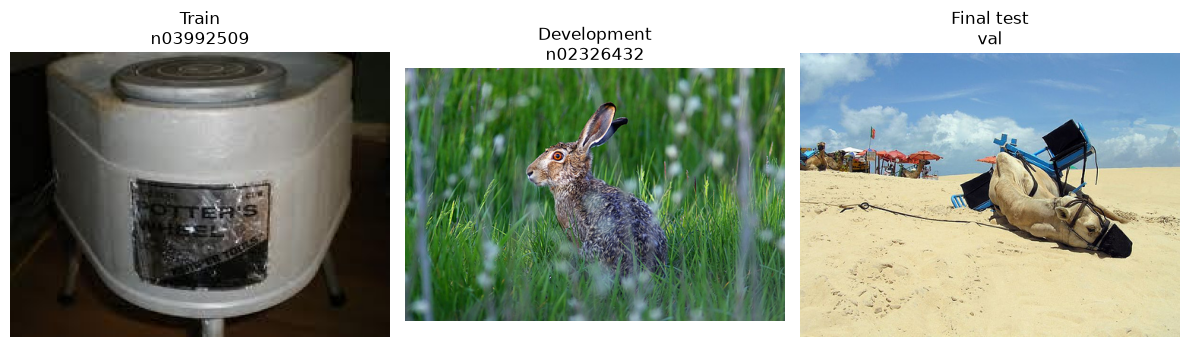

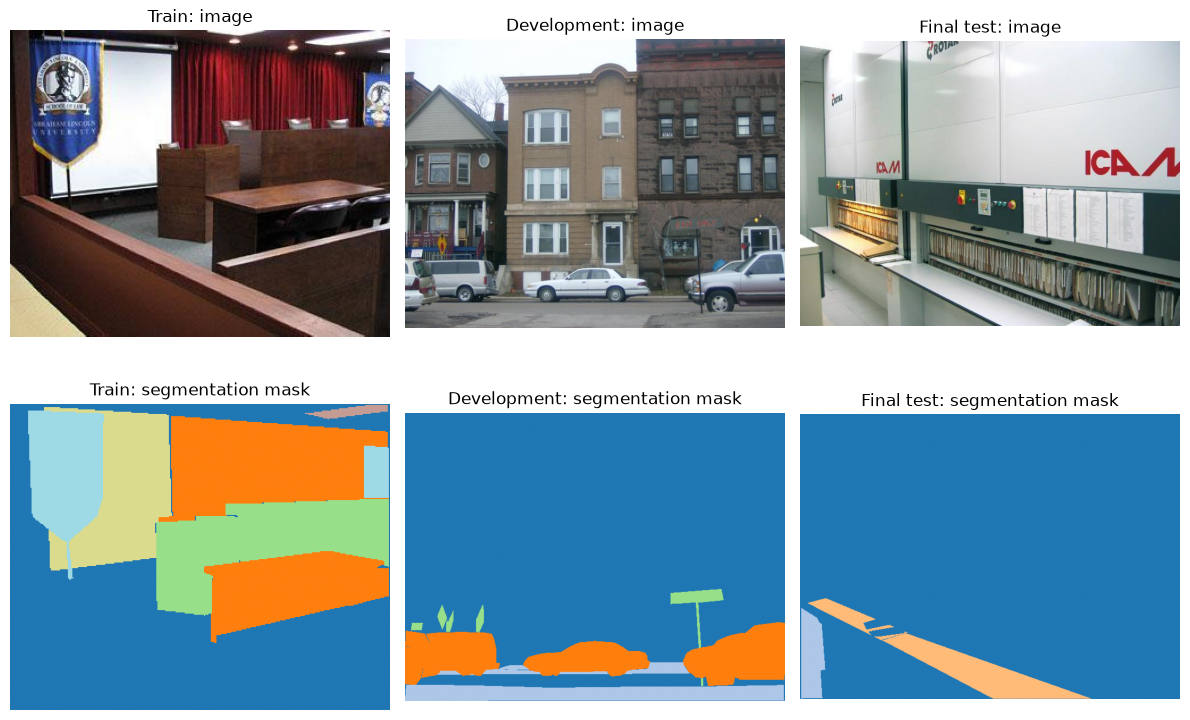

In [5]:
rng = np.random.default_rng(67)

IMAGENET_ROOT = PROJECT_ROOT / "datasets/imagenet"
ADE20K_ROOT = PROJECT_ROOT / "datasets/ade20k/ADEChallengeData2016"

# ImageNet: randomly select one image from each split.
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, (name, paths) in zip(axes, [
    ("Train", im_train),
    ("Development", im_dev),
    ("Final test", im_test)
]):
    path = paths[int(rng.integers(len(paths)))]

    with Image.open(IMAGENET_ROOT / path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(f"{name}\n{Path(path).parent.name}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# ADE20K: display an image and its matching mask.
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for col, (name, entries) in enumerate([
    ("Train", ade_train),
    ("Development", ade_dev),
    ("Final test", ade_test)
]):
    entry = entries[int(rng.integers(len(entries)))]

    with Image.open(ADE20K_ROOT / entry["image"]) as img:
        image = np.asarray(img.convert("RGB"))

    with Image.open(ADE20K_ROOT / entry["mask"]) as m:
        mask = np.asarray(m)

    axes[0, col].imshow(image)
    axes[0, col].set_title(f"{name}: image")
    axes[0, col].axis("off")

    axes[1, col].imshow(mask, cmap="tab20", vmin=0, vmax=150)
    axes[1, col].set_title(f"{name}: segmentation mask")
    axes[1, col].axis("off")

    assert image.shape[:2] == mask.shape[:2]

plt.tight_layout()
plt.show()

# Download pretrained models + weights

In [12]:
# from huggingface_hub import notebook_login

# notebook_login(skip_if_logged_in=False)

Download models + checkpoint

In [6]:
ROOT = PROJECT_ROOT
SOURCE = ROOT / "models" / "source"
CHECKPOINTS = ROOT / "models" / "checkpoints"

SOURCE.mkdir(parents=True, exist_ok=True)
CHECKPOINTS.mkdir(parents=True, exist_ok=True)


def download_source(name, repository, required_file):
    """Download source code once; preserve existing source."""
    destination = SOURCE / name

    if (destination / required_file).is_file():
        print(f"[SKIP] Source already exists: {name}")
        return

    if destination.exists():
        raise RuntimeError(
            f"{destination} exists but is missing {required_file}. "
            "Inspect this folder before downloading into it."
        )

    print(f"[DOWNLOAD] Source: {name}", flush=True)

    # Record the exact revision used.
    request = Request(
        f"https://api.github.com/repos/{repository}/commits/HEAD",
        headers={"User-Agent": "vit-research-setup"},
    )
    with urlopen(request, timeout=120) as response:
        commit = json.load(response)["sha"]

    url = f"https://codeload.github.com/{repository}/zip/{commit}"

    # Download and extract temporarily; move only after completion.
    with tempfile.TemporaryDirectory(dir=SOURCE) as temporary:
        temporary = Path(temporary)
        archive = temporary / "source.zip"
        extracted = temporary / "extracted"

        with urlopen(url, timeout=120) as response:
            with archive.open("wb") as output:
                shutil.copyfileobj(response, output)

        with zipfile.ZipFile(archive) as zipped:
            zipped.extractall(extracted)

        source_folder = next(extracted.iterdir())

        if not (source_folder / required_file).is_file():
            raise RuntimeError(f"Downloaded source is missing {required_file}")

        (source_folder / "SOURCE_REVISION.json").write_text(
            json.dumps(
                {"repository": repository, "commit": commit},
                indent=2,
            ),
            encoding="utf-8",
        )

        shutil.move(str(source_folder), str(destination))

    print(f"[SAVED] {destination}")


def download_checkpoint(url, model_name, filename):
    """Download a checkpoint or config file if it is missing."""
    destination = CHECKPOINTS / model_name / filename
    destination.parent.mkdir(parents=True, exist_ok=True)

    if destination.is_file() and destination.stat().st_size > 0:
        print(f"[SKIP] Already exists: {model_name}/{filename}")
        return

    temporary = destination.with_name(destination.name + ".part")
    print(f"[DOWNLOAD] {model_name}/{filename}", flush=True)

    with urlopen(url, timeout=120) as response:
        expected_size = response.headers.get("Content-Length")
        downloaded = 0

        with temporary.open("wb") as output:
            while chunk := response.read(1024 * 1024):
                output.write(chunk)
                downloaded += len(chunk)

        if expected_size and downloaded != int(expected_size):
            raise RuntimeError(f"Incomplete download: {filename}")

        if downloaded == 0:
            raise RuntimeError(f"Empty download: {filename}")

    temporary.replace(destination)
    print(f"[SAVED] {filename}: {downloaded / 1024**2:.1f} MiB")


# ------------------------------------------------------------
# 1. SOURCE CODE
# These are source repositories, not additional model weights.
# SigLIP 2 uses Transformers; RADIO also uses timm.
# ------------------------------------------------------------

download_source(
    "dinov2",
    "facebookresearch/dinov2",
    "dinov2/models/vision_transformer.py",
)

download_source(
    "siglip2",
    "huggingface/transformers",
    "src/transformers/__init__.py",
)

download_source(
    "radio",
    "NVlabs/RADIO",
    "hubconf.py",
)

download_source(
    "timm",
    "huggingface/pytorch-image-models",
    "timm/models/vision_transformer.py",
)


# ------------------------------------------------------------
# 2. CHECKPOINTS AND CONFIGURATION
# ------------------------------------------------------------

# DINOv2 ViT-B/14 — standard version without register tokens.
download_checkpoint(
    "https://dl.fbaipublicfiles.com/dinov2/"
    "dinov2_vitb14/dinov2_vitb14_pretrain.pth",
    "dinov2",
    "dinov2_vitb14_pretrain.pth",
)

# SigLIP 2 Base/16 — 224 × 224 variant.
# The published checkpoint includes both vision and text encoders.
siglip_url = (
    "https://huggingface.co/google/"
    "siglip2-base-patch16-224/resolve/main"
)

for filename in [
    "model.safetensors",
    "config.json",
    "preprocessor_config.json",
    "tokenizer.json",
    "tokenizer.model",
    "tokenizer_config.json",
    "special_tokens_map.json",
]:
    download_checkpoint(
        f"{siglip_url}/{filename}",
        "siglip2",
        filename,
    )

# RADIOv2.5-B.
download_checkpoint(
    "https://huggingface.co/nvidia/RADIO/resolve/main/"
    "radio-v2.5-b_half.pth.tar",
    "radio",
    "radio-v2.5-b_half.pth.tar",
)

print(f"\nSource:      {SOURCE}")
print(f"Checkpoints: {CHECKPOINTS}")
print("Downloads complete.  Runtime installation and model loading are separate.")
# Existing files are checked for presence, not verified for corruption.

[SKIP] Source already exists: dinov2
[SKIP] Source already exists: siglip2
[SKIP] Source already exists: radio
[SKIP] Source already exists: timm
[SKIP] Already exists: dinov2/dinov2_vitb14_pretrain.pth
[SKIP] Already exists: siglip2/model.safetensors
[SKIP] Already exists: siglip2/config.json
[SKIP] Already exists: siglip2/preprocessor_config.json
[SKIP] Already exists: siglip2/tokenizer.json
[SKIP] Already exists: siglip2/tokenizer.model
[SKIP] Already exists: siglip2/tokenizer_config.json
[SKIP] Already exists: siglip2/special_tokens_map.json
[SKIP] Already exists: radio/radio-v2.5-b_half.pth.tar

Source:      /root/work/DeepLearning-Project/models/source
Checkpoints: /root/work/DeepLearning-Project/models/checkpoints
Downloads complete.  Runtime installation and model loading are separate.


create segmentation and classification head 

In [7]:
# Both reports construct the same backbone, preprocessing and task heads.
import baseline_models
importlib.reload(baseline_models)

ROOT = PROJECT_ROOT
SOURCE = ROOT / "models/source"
CHECKPOINTS = ROOT / "models/checkpoints"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def BaselineModel(name):
    return baseline_models.BaselineModel(name, root=ROOT)


print("Shared model setup:", baseline_models.__file__)
print("Device:", DEVICE)


Shared model setup: /root/work/DeepLearning-Project/baseline_models.py
Device: cuda


# run baseline checkpoints 

In [15]:
# Models are constructed by the runner; avoid keeping an extra GPU/CPU model resident.


448 × 448 LoRA baselines for ImageNet and ADE20K.  Training uses BF16, one-image microbatches, 16 accumulation steps, and gradient clipping at 1.0.  Validation uses batch 1; FP32 benchmarks use batches 1 and 2.  Accumulation uses valid-target weighting and flushes the final partial window.  Best/last checkpoints and finite-loss/gradient audits remain enabled.  These are conservative starting settings for the RTX 4060 Laptop GPU with 8 GB VRAM and 16 GB RAM, not a guarantee of fitting VRAM.


In [12]:
import importlib
import inspect
from pathlib import Path
import baseline_runner

importlib.reload(baseline_runner)

required_options = {
    "TRAINING_MODE", "LORA_R", "LORA_ALPHA", "LORA_LR", "TASKS",
    "TRAIN_PRECISION", "LOADER_BACKEND", "FAIL_FAST",
    "MICRO_BATCH_SIZE", "GRAD_ACCUM_STEPS", "EVAL_BATCH_SIZE",
}
missing = required_options - set(
    inspect.signature(baseline_runner.run_baselines).parameters
)
if missing:
    raise RuntimeError(
        f"Runner at {baseline_runner.__file__} is missing: {sorted(missing)}.  "
        "Replace it with the updated baseline_runner.py and restart the kernel."
    )

print("Runner:", Path(baseline_runner.__file__).resolve())

ROOT = PROJECT_ROOT
SOURCE = ROOT / "models/source"
CHECKPOINTS = ROOT / "models/checkpoints"


# Local smoke settings (448x448, one epoch on the existing saved splits).
# Keep these non-Cropr settings matched in both notebooks for a controlled comparison.
# RTX 4090 comments are suggested starting points, not measured memory limits.
SEED = 42
SIZE = 448  # RTX 4090: keep 448x448.
MODEL_NAMES = ("dinov2", "siglip2", "radio")
TASKS = ("classification", "segmentation")
EPOCHS = {"classification": 10, "segmentation": 20}  # RTX 4090: {"classification": 10, "segmentation": 20}.

# Identical LoRA and task-head optimization in both reports.
LORA_R = 8
LORA_ALPHA = 16.0
LORA_LR = 1e-4
LORA_TARGETS = None
LR = {"classification": 1e-3, "segmentation": 1e-3}
WEIGHT_DECAY = 0.01
MAX_GRAD_NORM = 1.0
TRAIN_PRECISION = "bf16"
EVAL_TF32 = False
STRICT_DETERMINISM = False

# Effective training batch = microbatch x accumulation = 16 on either machine.
MICRO_BATCH_SIZE = 8  # RTX 4090: start with 4, including Cropr segmentation.
GRAD_ACCUM_STEPS = 2  # RTX 4090: 4 when microbatch is 4.

EVAL_BATCH_SIZE = 16  # RTX 4090: start with 8; evaluation is FP32.
BATCH_SIZE = 2  # Keep benchmark batch 2 in both reports for comparable timings.
NUM_WORKERS = 16  # RTX 4090 cloud host: try 8 if CPU/storage support it.
LOADER_BACKEND = "thread"
FAIL_FAST = True

# Short smoke measurements; use the commented settings for final measurements.
BENCH_WARMUP = 2  # RTX 4090 / final measurements: 10.
BENCH_REPEATS = 5  # RTX 4090 / final measurements: 50.
BENCH_TRIALS = 1  # RTX 4090 / final measurements: 3.
FLOP_BATCHES = 1  # RTX 4090 / final measurements: 3.
PROFILE_REPEATS = 1  # RTX 4090 / final measurements: 3.

TRAINING_MODE = "lora"
# Feature caching applies only to the optional cached_head mode.
CACHE_ROOT = ROOT / "baseline feature cache"
CACHE_BATCH_SIZE = 1
KEEP_CACHE = False

results, OUT = baseline_runner.run_baselines(
    BaselineModel,
    ROOT=ROOT,
    SEED=SEED,
    SIZE=SIZE,
    MODEL_NAMES=MODEL_NAMES,
    TASKS=TASKS,
    TRAINING_MODE=TRAINING_MODE,
    TRAIN_PRECISION=TRAIN_PRECISION,
    LORA_R=LORA_R,
    LORA_ALPHA=LORA_ALPHA,
    LORA_LR=LORA_LR,
    MAX_GRAD_NORM=MAX_GRAD_NORM,
    LORA_TARGETS=LORA_TARGETS,
    EVAL_TF32=EVAL_TF32,
    STRICT_DETERMINISM=STRICT_DETERMINISM,
    EPOCHS=EPOCHS,
    BATCH_SIZE=BATCH_SIZE,
    MICRO_BATCH_SIZE=MICRO_BATCH_SIZE,
    GRAD_ACCUM_STEPS=GRAD_ACCUM_STEPS,
    EVAL_BATCH_SIZE=EVAL_BATCH_SIZE,
    LR=LR,
    WEIGHT_DECAY=WEIGHT_DECAY,
    NUM_WORKERS=NUM_WORKERS,
    LOADER_BACKEND=LOADER_BACKEND,
    FAIL_FAST=FAIL_FAST,
    CACHE_ROOT=CACHE_ROOT,
    CACHE_BATCH_SIZE=CACHE_BATCH_SIZE,
    KEEP_CACHE=KEEP_CACHE,
    BENCH_WARMUP=BENCH_WARMUP,
    BENCH_REPEATS=BENCH_REPEATS,
    BENCH_TRIALS=BENCH_TRIALS,
    FLOP_BATCHES=FLOP_BATCHES,
    PROFILE_REPEATS=PROFILE_REPEATS,
)

print("Training microbatch / accumulation / effective batch:", MICRO_BATCH_SIZE, GRAD_ACCUM_STEPS, MICRO_BATCH_SIZE * GRAD_ACCUM_STEPS)
print("Validation batch / benchmark batch:", EVAL_BATCH_SIZE, BATCH_SIZE)
print("Run folder:", OUT)
print("Training mode:", TRAINING_MODE)
print("Training precision:", TRAIN_PRECISION)
print("Image loader:", LOADER_BACKEND, "| workers:", NUM_WORKERS)
print(
    "LoRA checkpoints: best_lora.pt / last_lora.pt (adapters + head)."
    if TRAINING_MODE == "lora"
    else "Frozen checkpoints: best_head.pt / last_head.pt."
)

Runner: /root/work/DeepLearning-Project/report_1/baseline_runner.py


Validate classification/train:   0%|          | 0/100000 [00:00<?, ?files/s]

Validate classification/dev:   0%|          | 0/20000 [00:00<?, ?files/s]

Validate classification/val:   0%|          | 0/50000 [00:00<?, ?files/s]

classification {'train': 100000, 'dev': 20000, 'val': 50000}


...

  train loss=0.2161 | dev miou_pct=49.89 | train=5.3 min | peak=5.63 GiB


USDT:2026-10-25 22:23:57 422067:422067 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-25 22:23:57 422067:422067 SyncActivityProfilerHandler.cpp:46] profiler_stop


Evaluate segmentation:   0%|          | 0/125 [00:00<?, ?batch/s]

USDT:2026-10-25 22:24:14 422067:422067 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-25 22:24:14 422067:422067 SyncActivityProfilerHandler.cpp:46] profiler_stop



Finished.  Measurements saved to:
/root/work/DeepLearning-Project/report_1/baseline measurments/baseline measurments.csv
/root/work/DeepLearning-Project/report_1/baseline measurments/dinov2/latest/baseline measurements.csv
/root/work/DeepLearning-Project/report_1/baseline measurments/siglip2/latest/baseline measurements.csv
/root/work/DeepLearning-Project/report_1/baseline measurments/radio/latest/baseline measurements.csv
classification dinov2 → completed
classification siglip2 → completed
classification radio → completed
segmentation dinov2 → completed
segmentation siglip2 → completed
segmentation radio → completed
Training microbatch / accumulation / effective batch: 8 2 16
Validation batch / benchmark batch: 16 2
Run folder: /root/work/DeepLearning-Project/report_1/baseline measurments
Training mode: lora
Training precision: bf16
Image loader: thread | workers: 16
LoRA checkpoints: best_lora.pt / last_lora.pt (adapters + head).


graphs n stuff to check baseline measurments 

In [ ]:
# import importlib
# import torch
# import baseline_runner

# if not torch.cuda.is_available():
#     raise RuntimeError("Select the CUDA notebook kernel before profiling.")

# importlib.reload(baseline_runner)

# RUN_FOLDER = ROOT / "report_2" / "cropr measurments"

# targets = [
#     ("dinov2", ("classification", "segmentation")),
#     ("radio", ("classification",)),
# ]

# for model_name, tasks_to_refresh in targets:
#     rows, _ = baseline_runner.refresh_component_timings(
#         BaselineModel,
#         RUN_FOLDER / model_name / "latest",
#         ROOT=ROOT,
#         MODEL_NAMES=(model_name,),
#         TASKS=tasks_to_refresh,
#         PROFILE_REPEATS=10,
#         WARMUP=10,
#     )

#     for row in rows:
#         if row["model"] == model_name and row["task"] in tasks_to_refresh:
#             print(
#                 model_name,
#                 row["task"],
#                 "available:", row.get("component_gpu_attribution_available"),
#                 "reason:", row.get("component_gpu_attribution_reason"),
#             )

Results: /root/work/DeepLearning-Project/report_1/baseline measurments
Training mode: lora
Completed experiments: 6 / 6


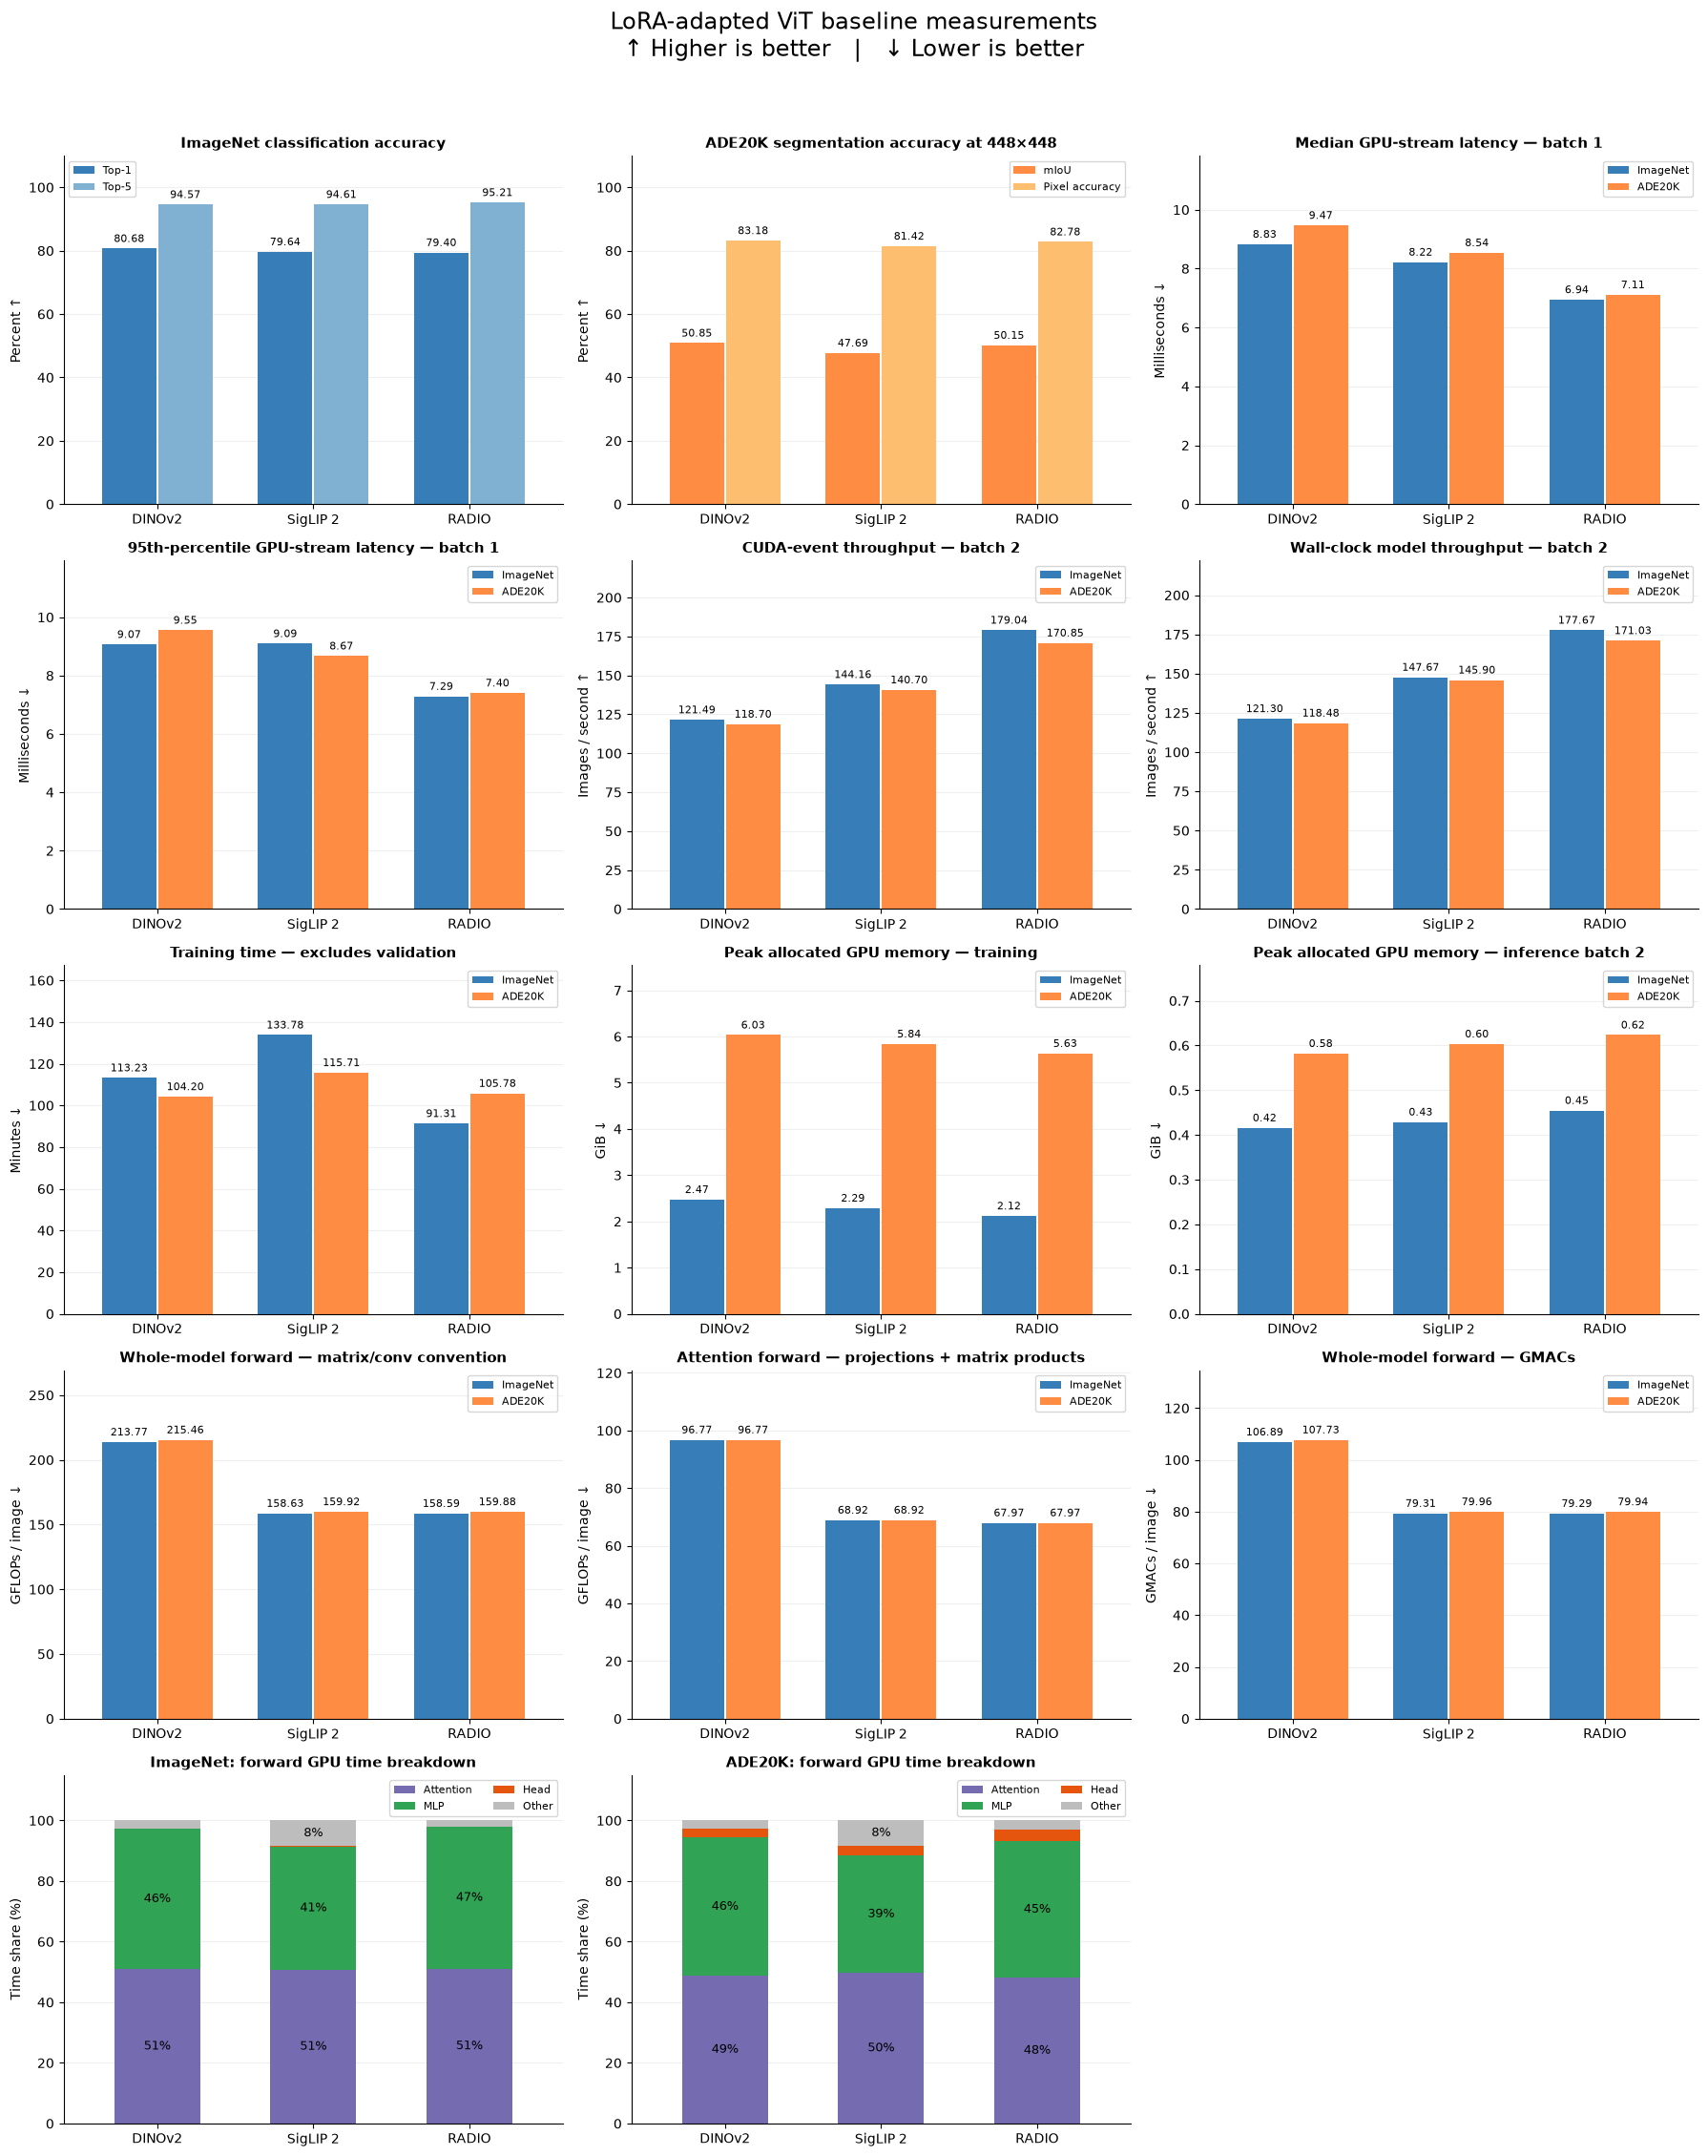

Training time scope: uncached RGB adapter + head training
LoRA inference uses merged adapters.
Forward counts: matrix multiplications, convolutions, and dense attention products.
Convention: 2 FLOPs per MAC; GMACs = GFLOPs / 2.
Excludes softmax, normalization, activations, interpolation, pooling, sorting, and elementwise work.
Coverage flags refer to this convention, not every arithmetic instruction.
Legacy partial profiler FLOPs are not used in these compute plots.
Throughput error bars show sample standard deviation across timing trials.
With one timing trial, no standard-deviation error bar is available.
Inference timing excludes data loading and GPU transfers.
Wall-clock throughput includes CPU launch overhead.
GPU-time shares are not FLOP shares.
Compare training time only with matching epoch budgets and dataset sizes.


In [10]:
# Graphs always read each model's stable latest folder; they do not use OUT.
RUN_FOLDER = REPORT1_DIR / "baseline measurments"


def load_selected_run(folder=None):
    run_path = Path(folder or RUN_FOLDER).expanduser().resolve()
    latest_files = sorted(run_path.glob("*/latest/baseline measurements.csv"))
    if latest_files:
        raw = pd.concat([pd.read_csv(path) for path in latest_files], ignore_index=True)
        configs = [json.loads((path.parent / "configuration.json").read_text(encoding="utf-8")) for path in latest_files]
        config = configs[0]
        if any(item.get("training_mode") != config.get("training_mode") for item in configs[1:]):
            raise ValueError("Latest model folders contain mixed training modes.")
    else:
        # Explicit legacy timestamped run folder.
        config = json.loads((run_path / "configuration.json").read_text(encoding="utf-8"))
        raw = pd.read_csv(run_path / "baseline measurments.csv")
    completed = raw.loc[raw["status"].eq("completed")].copy()
    if completed.empty:
        raise ValueError(f"No completed experiments in {run_path}.  Inspect the runner's error files.")
    if "training_mode" not in completed:
        completed["training_mode"] = config.get("training_mode", "unknown")
    modes = completed["training_mode"].dropna().unique()
    if len(modes) != 1 or modes[0] not in ("cached_head", "lora"):
        raise ValueError("Use one verified training mode per run; do not mix frozen and LoRA rows.")
    mode = str(modes[0])
    if config.get("training_mode", mode) != mode:
        raise ValueError("Results and run configuration disagree about training mode.")
    if mode == "lora":
        if "inference_lora_merged" not in completed or not completed["inference_lora_merged"].astype(str).str.lower().isin(["true", "1", "1.0"]).all():
            raise ValueError("LoRA inference rows must record merged adapters.")
    if completed.duplicated(["task", "model"]).any():
        raise ValueError("Duplicate task/model rows found.")
    return run_path, config, raw, completed, mode


run, run_config, results, df, training_mode = load_selected_run(RUN_FOLDER)
mode_label = "LoRA-adapted ViT" if training_mode == "lora" else "Frozen ViT"
print("Results:", run)
print("Training mode:", training_mode)
print(f"Completed experiments: {len(df)} / {len(results)}")

models = ["dinov2", "siglip2", "radio"]
model_labels = ["DINOv2", "SigLIP 2", "RADIO"]
tasks = ["classification", "segmentation"]
task_labels = ["ImageNet", "ADE20K"]
colors = ["#377eb8", "#ff8c42"]

batches = pd.to_numeric(df["batch_size"], errors="coerce").dropna().unique()
if len(batches) != 1:
    raise ValueError("Use the same batch size across experiments.")
batch = int(batches[0])

resolutions = pd.to_numeric(
    df["resolution"], errors="coerce"
).dropna().unique()
if len(resolutions) != 1:
    raise ValueError("Use the same resolution across experiments.")
size = int(resolutions[0])

df["training_minutes"] = pd.to_numeric(
    df["training_seconds"], errors="coerce"
) / 60

WHOLE = "whole_model_forward_gflops_per_image"
ATTENTION = "attention_forward_gflops_per_image"
GMACS = "whole_model_forward_gmacs_per_image"

coverage_flags = {
    WHOLE: "whole_model_flops_coverage_ok",
    ATTENTION: "attention_flops_coverage_ok",
    GMACS: "whole_model_flops_coverage_ok",
}


def true_flags(series):
    return (
        series.astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "1.0"])
    )


def values(task, metric):
    subset = df.loc[df["task"] == task].set_index("model")

    if metric not in subset:
        return np.full(len(models), np.nan)

    data = pd.to_numeric(subset[metric], errors="coerce")

    flag = coverage_flags.get(metric)
    if metric.endswith("_gpu_time_pct"):
        flag = "component_gpu_attribution_available"

    if flag is not None:
        if flag not in subset:
            return np.full(len(models), np.nan)
        data = data.where(true_flags(subset[flag]))

    return data.reindex(models).to_numpy(dtype=float)


def setup_axis(ax, title, ylabel):
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.set_xticks(np.arange(len(models)), model_labels)
    ax.set_xlim(-0.6, len(models) - 0.4)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def bars(ax, x, y, color, label, errors=None):
    valid = np.isfinite(y)
    if not valid.any():
        return []

    plotted = ax.bar(
        x[valid], y[valid], width=0.35,
        color=color, label=label,
    )
    ax.bar_label(
        plotted,
        labels=[f"{v:.2f}" for v in y[valid]],
        padding=3, fontsize=8,
    )

    upper = y[valid].tolist()

    if errors is not None:
        valid_error = valid & np.isfinite(errors) & (errors >= 0)
        if valid_error.any():
            ax.errorbar(
                x[valid_error], y[valid_error],
                yerr=errors[valid_error],
                fmt="none", ecolor="black", capsize=4,
            )
            upper.extend((y[valid_error] + errors[valid_error]).tolist())

    return upper


def comparison(ax, metric, title, ylabel, error_metric=None):
    setup_axis(ax, title, ylabel)
    upper = []

    for i, task in enumerate(tasks):
        x = np.arange(len(models)) + (i - 0.5) * 0.36
        errors = values(task, error_metric) if error_metric else None
        upper.extend(
            bars(
                ax, x, values(task, metric),
                colors[i], task_labels[i], errors,
            )
        )

    maximum = max(upper) if upper else 0
    ax.set_ylim(0, maximum * 1.25 if maximum > 0 else 1)

    if upper:
        ax.legend(fontsize=8)
    else:
        message = (
            "Missing / coverage not verified"
            if metric in coverage_flags else "Not available"
        )
        ax.text(
            0.5, 0.5, message,
            transform=ax.transAxes,
            ha="center", va="center", fontsize=9,
        )


fig, axes = plt.subplots(5, 3, figsize=(18, 23))
axes = axes.ravel()

# Accuracy.
accuracy_panels = [
    (
        axes[0], "classification",
        "ImageNet classification accuracy",
        [
            ("heldout_top1_pct", "Top-1", "#377eb8"),
            ("heldout_top5_pct", "Top-5", "#80b1d3"),
        ],
    ),
    (
        axes[1], "segmentation",
        f"ADE20K segmentation accuracy at {size}×{size}",
        [
            ("heldout_miou_pct", "mIoU", "#ff8c42"),
            ("heldout_pixel_accuracy_pct", "Pixel accuracy", "#fdbf6f"),
        ],
    ),
]

for ax, task, title, metrics in accuracy_panels:
    setup_axis(ax, title, "Percent ↑")
    for i, (metric, label, color) in enumerate(metrics):
        x = np.arange(len(models)) + (i - 0.5) * 0.36
        bars(ax, x, values(task, metric), color, label)
    ax.set_ylim(0, 110)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=8)

# Speed, memory, and corrected forward counts.
panels = [
    (
        "b1_latency_median_ms",
        "Median GPU-stream latency — batch 1",
        "Milliseconds ↓", None,
    ),
    (
        "b1_latency_p95_ms",
        "95th-percentile GPU-stream latency — batch 1",
        "Milliseconds ↓", None,
    ),
    (
        f"b{batch}_images_per_second",
        f"CUDA-event throughput — batch {batch}",
        "Images / second ↑",
        f"b{batch}_images_per_second_std",
    ),
    (
        f"b{batch}_wall_images_per_second",
        f"Wall-clock model throughput — batch {batch}",
        "Images / second ↑",
        f"b{batch}_wall_images_per_second_std",
    ),
    (
        "training_minutes",
        "Training time — excludes validation",
        "Minutes ↓", None,
    ),
    (
        "train_peak_allocated_gib",
        "Peak allocated GPU memory — training",
        "GiB ↓", None,
    ),
    (
        f"b{batch}_peak_allocated_gib",
        f"Peak allocated GPU memory — inference batch {batch}",
        "GiB ↓", None,
    ),
    (
        WHOLE,
        "Whole-model forward — matrix/conv convention",
        "GFLOPs / image ↓", None,
    ),
    (
        ATTENTION,
        "Attention forward — projections + matrix products",
        "GFLOPs / image ↓", None,
    ),
    (
        GMACS,
        "Whole-model forward — GMACs",
        "GMACs / image ↓", None,
    ),
]

for ax, (metric, title, ylabel, error_metric) in zip(axes[2:12], panels):
    comparison(ax, metric, title, ylabel, error_metric)

# GPU-time breakdown.
parts = ["attention", "mlp", "head", "other"]
part_colors = ["#756bb1", "#31a354", "#e6550d", "#bdbdbd"]

for ax, task, label in zip(axes[12:14], tasks, task_labels):
    setup_axis(ax, f"{label}: forward GPU time breakdown", "Time share (%)")

    data = np.array([
        values(task, f"{part}_gpu_time_pct") for part in parts
    ])
    valid = np.isfinite(data).all(axis=0)
    x = np.arange(len(models))[valid]
    bottom = np.zeros(valid.sum())

    if valid.any():
        for i, part in enumerate(parts):
            heights = data[i, valid]
            ax.bar(
                x, heights, bottom=bottom, width=0.55,
                color=part_colors[i],
                label="MLP" if part == "mlp" else part.title(),
            )
            for position, height, base in zip(x, heights, bottom):
                if height >= 7:
                    ax.text(
                        position, base + height / 2, f"{height:.0f}%",
                        ha="center", va="center", fontsize=9,
                    )
            bottom += heights

        ax.legend(fontsize=8, ncol=2)

        for position in np.arange(len(models))[~valid]:
            ax.text(position, 3, "N/A", ha="center", color="gray")
    else:
        ax.text(
            0.5, 0.5, "GPU attribution unavailable",
            transform=ax.transAxes, ha="center", va="center",
        )

    ax.set_ylim(0, 115)

axes[14].set_visible(False)

fig.suptitle(
    f"{mode_label} baseline measurements\n"
    "↑ Higher is better   |   ↓ Lower is better",
    fontsize=17,
)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

print("Training time scope:", run_config.get("training_seconds_scope", "See result.json"))
print("LoRA inference uses merged adapters." if training_mode == "lora" else "Inference uses the full frozen RGB backbone.")
print(
    "Forward counts: matrix multiplications, convolutions, and dense attention products.\n"
    "Convention: 2 FLOPs per MAC; GMACs = GFLOPs / 2.\n"
    "Excludes softmax, normalization, activations, interpolation, pooling, "
    "sorting, and elementwise work.\n"
    "Coverage flags refer to this convention, not every arithmetic instruction.\n"
    "Legacy partial profiler FLOPs are not used in these compute plots.\n"
    "Throughput error bars show sample standard deviation across timing trials.\n"
    "With one timing trial, no standard-deviation error bar is available.\n"
    "Inference timing excludes data loading and GPU transfers.\n"
    "Wall-clock throughput includes CPU launch overhead.\n"
    "GPU-time shares are not FLOP shares.\n"
    "Compare training time only with matching epoch budgets and dataset sizes."
)

for metric in (WHOLE, ATTENTION):
    if not any(np.isfinite(values(task, metric)).any() for task in tasks):
        print(
            f"\nMissing or unverified: {metric}\n"
            "For an older run, use add_forward_flops_to_run(...).\n"
            "For an updated run, inspect forward_flops.json, flop_samples/, "
            "and any FLOP error file."
        )

In [ ]:
for path in RUN_FOLDER.rglob("*"):
    if path.is_file() and "profil" in path.name.lower():
        print(path.relative_to(RUN_FOLDER))

classification_dinov2\profiling.json
classification_radio\profiling.json
classification_siglip2\profiling.json
segmentation_dinov2\profiling.json
segmentation_radio\profiling.json
segmentation_siglip2\profiling.json


In [ ]:
import json
from pprint import pprint

path = RUN_FOLDER / "radio" / "latest" / "classification" / "profiling.json"
pprint(json.loads(path.read_text(encoding="utf-8")))

{'attention_counted_partial_gflops_per_image': 67.968958464,
 'attention_flops_convention': 'dense_matmul_2_flops_per_mac',
 'attention_flops_counter_version': 3,
 'attention_flops_coverage_ok': True,
 'attention_flops_uncounted_modules': '',
 'attention_flops_unmapped_ops': '',
 'attention_forward_gflops_batch_mean_max': 67.968958464,
 'attention_forward_gflops_batch_mean_min': 67.968958464,
 'attention_forward_gflops_batch_mean_std': 0.0,
 'attention_forward_gflops_per_image': 67.968958464,
 'attention_gpu_time_pct': None,
 'attention_gpu_time_us': 0.0,
 'attention_module_count': 12,
 'attention_parameters': 28348416,
 'attention_trainable_parameters': 0,
 'batch_size': 2,
 'component_gpu_attribution_available': False,
 'component_gpu_attribution_reason': 'No CUDA time attributed to CPU '
                                     'operations inside the forward scope.; No '
                                     'CUDA time attributed to matched '
                                     'attenti

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

import json

# Always load the stable per-model latest folders; do not use OUT.
RUN_FOLDER = REPORT1_DIR / "baseline measurments"

def load_selected_run(folder=None):
    run_path = Path(folder or RUN_FOLDER).expanduser().resolve()
    latest_files = sorted(run_path.glob("*/latest/baseline measurements.csv"))
    if latest_files:
        raw = pd.concat([pd.read_csv(path) for path in latest_files], ignore_index=True)
        configs = [json.loads((path.parent / "configuration.json").read_text(encoding="utf-8")) for path in latest_files]
        config = configs[0]
        if any(item.get("training_mode") != config.get("training_mode") for item in configs[1:]):
            raise ValueError("Latest model folders contain mixed training modes.")
    else:
        # Explicit legacy timestamped run folder.
        config = json.loads((run_path / "configuration.json").read_text(encoding="utf-8"))
        raw = pd.read_csv(run_path / "baseline measurments.csv")
    completed = raw.loc[raw["status"].eq("completed")].copy()
    if completed.empty:
        raise ValueError(f"No completed experiments in {run_path}.  Inspect the runner's error files.")
    if "training_mode" not in completed:
        completed["training_mode"] = config.get("training_mode", "unknown")
    modes = completed["training_mode"].dropna().unique()
    if len(modes) != 1 or modes[0] not in ("cached_head", "lora"):
        raise ValueError("Use one verified training mode per run; do not mix frozen and LoRA rows.")
    mode = str(modes[0])
    if config.get("training_mode", mode) != mode:
        raise ValueError("Results and run configuration disagree about training mode.")
    if mode == "lora":
        if "inference_lora_merged" not in completed or not completed["inference_lora_merged"].astype(str).str.lower().isin(["true", "1", "1.0"]).all():
            raise ValueError("LoRA inference rows must record merged adapters.")
    if completed.duplicated(["task", "model"]).any():
        raise ValueError("Duplicate task/model rows found.")
    return run_path, config, raw, completed, mode


run, run_config, raw, df, training_mode = load_selected_run(RUN_FOLDER)
mode_label = "LoRA-adapted ViT" if training_mode == "lora" else "Frozen ViT"
print("Results:", run)
print("Training mode:", training_mode)

model_names = {
    "dinov2": "DINOv2",
    "siglip2": "SigLIP 2",
    "radio": "RADIO",
}
task_names = {
    "classification": "ImageNet",
    "segmentation": "ADE20K",
}

order = pd.MultiIndex.from_product(
    [list(task_names), list(model_names)],
    names=["task", "model"],
)
df = df.set_index(["task", "model"]).reindex(order)

def numeric(column):
    if column not in df:
        return np.full(len(df), np.nan)
    return pd.to_numeric(df[column], errors="coerce").to_numpy(float)

def flag(column):
    if column not in df:
        return np.zeros(len(df), dtype=bool)
    return (
        df[column].astype(str).str.lower()
        .isin(["true", "1", "1.0"]).to_numpy()
    )

batches = np.unique(numeric("batch_size")[np.isfinite(numeric("batch_size"))])
if len(batches) != 1:
    raise ValueError("These comparison tables require one shared batch size.")
batch = int(batches[0])

labels = pd.MultiIndex.from_tuples(
    [(task_names[t], model_names[m]) for t, m in order],
    names=["Dataset", "Model"],
)

# Each entry contains: (CSV field, displayed label, conversion factor).
groups = {
    "1. Task performance": [
        ("epochs", "Epochs", 1),
        ("best_epoch", "Best epoch", 1),
        ("heldout_top1_pct", "Top-1 (%) ↑", 1),
        ("heldout_top5_pct", "Top-5 (%) ↑", 1),
        ("heldout_miou_pct", "mIoU (%) ↑", 1),
        ("heldout_pixel_accuracy_pct", "Pixel accuracy (%) ↑", 1),
    ],
    "2. Full-model inference speed": [
        ("b1_latency_median_ms", "B1 median (ms) ↓", 1),
        ("b1_latency_p95_ms", "B1 p95 (ms) ↓", 1),
        (f"b{batch}_images_per_second", f"B{batch} CUDA images/s ↑", 1),
        (f"b{batch}_images_per_second_std", "CUDA trial SD", 1),
        (f"b{batch}_wall_images_per_second", f"B{batch} wall images/s ↑", 1),
        (f"b{batch}_wall_images_per_second_std", "Wall trial SD", 1),
    ],
    "3. Training and cache time — minutes": [
        ("training_seconds", "Training only (see scope below)", 1 / 60),
        ("cache_train_seconds", "Train cache", 1 / 60),
        ("cache_dev_seconds", "Dev cache", 1 / 60),
        ("head_training_seconds", "Head epochs only", 1 / 60),
        ("pipeline_fit_seconds_including_cache_dev_and_saves",
         "Cache + fit + dev + saves", 1 / 60),
        ("heldout_evaluation_seconds", "Held-out evaluation", 1 / 60),
    ],
    "4. GPU memory — GiB": [
        ("train_peak_allocated_gib", "Training allocated ↓", 1),
        ("train_peak_reserved_gib", "Training reserved ↓", 1),
        ("b1_peak_allocated_gib", "B1 inference allocated ↓", 1),
        (f"b{batch}_peak_allocated_gib",
         f"B{batch} inference allocated ↓", 1),
    ],
    "5. Forward operation counts — per image": [
        ("whole_model_forward_gflops_per_image", "Whole-model GFLOPs ↓", 1),
        ("attention_forward_gflops_per_image", "Attention GFLOPs ↓", 1),
        ("whole_model_forward_gmacs_per_image", "Whole-model GMACs ↓", 1),
    ],
    "6. Profiled forward GPU-time shares — percent": [
        ("attention_gpu_time_pct", "Attention", 1),
        ("mlp_gpu_time_pct", "MLP", 1),
        ("head_gpu_time_pct", "Head", 1),
        ("other_gpu_time_pct", "Other", 1),
    ],
    "7. Parameters and measurement samples": [
        ("backbone_parameters", "Backbone parameters (M)", 1e-6),
        ("trainable_head_parameters", "Head parameters (M)", 1e-6),
        ("trainable_lora_parameters", "Trained LoRA parameters (M)", 1e-6),
        ("attention_parameters", "Attention parameters (M)", 1e-6),
        ("attention_trainable_parameters", "Inference attention trainable parameters", 1),
        ("flops_sample_images", "FLOP sample images", 1),
        ("flops_sample_batches", "FLOP sample batches", 1),
        ("benchmark_trials", "Timing trials", 1),
    ],
}

if training_mode == "lora":
    groups["3. Training and cache time — minutes"] = [
        ("training_seconds", "RGB + LoRA/head training", 1 / 60),
        ("fit_seconds_including_dev_and_saves", "Fit + dev + saves + audits", 1 / 60),
        ("heldout_evaluation_seconds", "Held-out evaluation", 1 / 60),
    ]
    groups["8. LoRA configuration"] = [
        ("micro_batch_size", "Training microbatch", 1),
        ("grad_accum_steps", "Accumulation steps", 1),
        ("effective_train_batch_size", "Effective training batch", 1),
        ("eval_batch_size", "Validation/test batch", 1),
        ("lora_rank", "Rank", 1),
        ("lora_alpha", "Alpha", 1),
        ("lora_lr", "Adapter LR", 1),
        ("merge_max_absolute_logit_error", "Merge max logit error", 1),
    ]

numpy_tables = {}
display_tables = {}

def show_table(table, title):
    display(
        table.style
        .format(precision=6 if "LoRA configuration" in title else 2, na_rep="—")
        .set_caption(title)
        .set_table_styles([
            {"selector": "caption",
             "props": [("text-align", "left"), ("font-size", "16px"),
                       ("font-weight", "bold"), ("padding", "12px 0")]},
            {"selector": "th",
             "props": [("background-color", "#edf2f7"), ("color", "#172b4d"),
                       ("padding", "9px"), ("text-align", "left")]},
            {"selector": "td",
             "props": [("padding", "9px"), ("text-align", "right"),
                       ("border-bottom", "1px solid #e2e8f0")]},
        ])
    )

for title, specs in groups.items():
    columns = []

    for key, label, scale in specs:
        values = numeric(key) * scale

        # Unverified or unavailable measurements stay missing.
        if key.startswith("whole_model_forward_"):
            values = np.where(flag("whole_model_flops_coverage_ok"), values, np.nan)
        elif key == "attention_forward_gflops_per_image":
            values = np.where(flag("attention_flops_coverage_ok"), values, np.nan)
        elif key.endswith("_gpu_time_pct"):
            values = np.where(
                flag("component_gpu_attribution_available"), values, np.nan
            )

        columns.append(values)

    array = np.column_stack(columns)
    table = pd.DataFrame(
        array, index=labels, columns=[label for _, label, _ in specs]
    )

    numpy_tables[title] = array
    display_tables[title] = table
    show_table(table, f"{mode_label} | {title.replace('Training and cache time', 'Training time') if training_mode == 'lora' else title}")

# Retain every saved field for inspection, including diagnostic fields.
all_saved_fields = df.copy()
all_saved_fields.index = labels

print("— means unavailable or not applicable, never zero.")
print("Timing SD measures repeated benchmarking, not independent training runs.")
print("Training totals overlap with their components; do not add them together.")
print("All original CSV fields remain available in: all_saved_fields")
print("Training time scope:", run_config.get("training_seconds_scope", "See result.json"))
if training_mode == "lora":
    print("Trained LoRA parameter count describes adaptation; inference attention weights are frozen after merging.")
    print("Cache costs do not apply to LoRA runs.")


Results: /root/work/DeepLearning-Project/report_1/baseline measurments
Training mode: lora


— means unavailable or not applicable, never zero.
Timing SD measures repeated benchmarking, not independent training runs.
Training totals overlap with their components; do not add them together.
All original CSV fields remain available in: all_saved_fields
Training time scope: uncached RGB adapter + head training
Trained LoRA parameter count describes adaptation; inference attention weights are frozen after merging.
Cache costs do not apply to LoRA runs.
